# Эксперимент 4 · Исполнение коммуникационного протокола

Алиса знает строку $x$, Боб знает строку $y$. За первые $n$ раундов Алиса передаёт свой вход по биту. В раунде $n+1$ Боб отправляет бит результата. После раундов каждый отдельно сообщает итоговый ответ.

Выполни **Run All**, чтобы увидеть один разобранный эпизод, полный прогон Python-эталона и примеры промптов. Настройки входов находятся в разделе 8. Запуск с Codex включается в разделе 11. Повторная оценка по сохранённому журналу находится в разделе 12, графики — в разделе 13.

**Две проверки модели.** В `step` Codex отвечает по эталонной локальной истории. В `episode` каждый следующий ход опирается на то, что реально случилось в канале.

## 1. Данные и состояние игрока

- `Config.total_rounds` возвращает $n+1$ раундов связи.
- `Turn` хранит собственное действие и наблюдение. `View` хранит роль, свой вход и кортеж прошлых ходов. `round_number` равен длине истории плюс один. После последнего раунда это позиция итогового решения. `after()` создаёт новый `View`, поэтому старое состояние сохраняется для проверки.
- `Decision.token` обрезает пробелы по краям ответа. В журнал идёт исходная строка `raw_reply`.
- `Round` хранит два решения и результат канала. `Episode.decisions()` выдаёт решения в порядке Алиса → Боб для каждого раунда, а в конце отдаёт итоговые ответы.
- `Player` — любая функция, которая получает `View` и возвращает строку.

In [16]:
"""Пилот эксперимента 4. Python 3.10+, только стандартная библиотека."""

import argparse
import json
import os
import random
import shutil
import subprocess
from collections import Counter
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from functools import partial
from io import StringIO
from pathlib import Path
from tempfile import TemporaryDirectory
from typing import Callable, Iterator, TextIO


ALICE, BOB = "Alice", "Bob"
ACTIONS = {"SEND_0", "SEND_1", "LISTEN"}
ANSWERS = {"ANSWER_0", "ANSWER_1"}

FUNCTIONS = {
    "ip": "IP равна чётности числа позиций, где оба бита равны 1.",
    "disj": "DISJ равна 1, если ни в одной позиции оба бита не равны 1, иначе 0.",
}


@dataclass(frozen=True)
class Config:
    n: int
    function: str
    channel: str
    explanation: str

    @property
    def total_rounds(self) -> int:
        return self.n + 1


@dataclass(frozen=True)
class Turn:
    action: str
    observation: str | None


@dataclass(frozen=True)
class View:
    role: str
    own_input: str
    history: tuple[Turn, ...] = ()

    @property
    def round_number(self) -> int:
        return len(self.history) + 1

    def after(self, action: str, observation: str | None) -> "View":
        return View(self.role, self.own_input, self.history + (Turn(action, observation),))


@dataclass(frozen=True)
class Decision:
    view: View
    raw_reply: str

    @property
    def token(self) -> str:
        return self.raw_reply.strip()


@dataclass(frozen=True)
class Round:
    decisions: tuple[Decision, Decision]
    observations: tuple[str | None, str | None] | None


@dataclass
class Episode:
    rounds: list[Round]
    outputs: tuple[Decision, Decision] | None = None

    def decisions(self) -> Iterator[Decision]:
        for round_ in self.rounds:
            yield from round_.decisions
        if self.outputs is not None:
            yield from self.outputs


Player = Callable[[View], str]

## 2. Функция, канал и эталонный игрок

- `function_bit()` считает число позиций, где оба бита равны единице. Для IP возвращает его чётность, для DISJ проверяет, что это число равно нулю. Проверка итоговых ответов вычисляет правильный бит отдельно через `oracle_bit()`.
- `channel_step()` принимает два готовых действия. Возвращает пару наблюдений в порядке Алиса, Боб. При одновременном слушании результат зависит от настройки канала.
- `observed_bit()` переводит наблюдение в бит для вычисления. В пилоте при тишине или отсутствии наблюдения используется ноль, чтобы игру можно было продолжить после ошибочного хода.
- `reference_choice()` вычисляет ход одной роли. Боб восстанавливает строку Алисы из первых $n$ наблюдений и использует свой `own_input` как $y$.

In [17]:
def function_bit(function: str, x: str, y: str) -> int:
    overlap = sum(a == b == "1" for a, b in zip(x, y))
    return overlap % 2 if function == "ip" else int(overlap == 0)


def channel_step(
    alice: str, bob: str, channel: str
) -> tuple[str | None, str | None]:
    """Принимает два уже выбранных действия и выдаёт два наблюдения."""
    if alice == bob == "LISTEN":
        symbol = "SILENCE" if channel == "silence" else "0"
        return symbol, symbol
    if alice == "LISTEN":
        return bob[-1], None
    if bob == "LISTEN":
        return None, alice[-1]
    return None, None


def observed_bit(turn: Turn) -> str:
    # После отклонения SILENCE или отсутствие наблюдения трактуем как 0.
    return "1" if turn.observation == "1" else "0"


def reference_choice(config: Config, view: View) -> str:
    """Правило одной роли. У функции нет доступа к чужому входу."""
    r = view.round_number
    if r <= config.n:
        if view.role == ALICE:
            return f"SEND_{view.own_input[r - 1]}"
        return "LISTEN"

    if view.role == ALICE:
        if r == config.total_rounds:
            return "LISTEN"
        return f"ANSWER_{observed_bit(view.history[-1])}"

    received_x = "".join(observed_bit(turn) for turn in view.history[:config.n])
    result = function_bit(config.function, received_x, view.own_input)
    if r == config.total_rounds:
        return f"SEND_{result}"
    return f"ANSWER_{result}"

## 3. Симуляция эпизода

`play()` сначала получает оба действия и только затем вызывает канал. Каждый игрок получает свою часть истории. При недопустимом токене раунд записывается с `observations = None` и игра останавливается. При состоявшемся столкновении записывается пара `(None, None)`. После последнего раунда симулятор запрашивает два итоговых ответа отдельно от канала.

In [18]:
def play(config: Config, x: str, y: str, alice: Player, bob: Player) -> Episode:
    """Вызывает игроков с разными локальными представлениями."""
    alice_view, bob_view = View(ALICE, x), View(BOB, y)
    episode = Episode([])

    for _ in range(config.total_rounds):
        a = Decision(alice_view, alice(alice_view))
        b = Decision(bob_view, bob(bob_view))
        if a.token not in ACTIONS or b.token not in ACTIONS:
            episode.rounds.append(Round((a, b), None))
            return episode

        observations = channel_step(a.token, b.token, config.channel)
        episode.rounds.append(Round((a, b), observations))
        alice_view = alice_view.after(a.token, observations[0])
        bob_view = bob_view.after(b.token, observations[1])

    episode.outputs = (
        Decision(alice_view, alice(alice_view)),
        Decision(bob_view, bob(bob_view)),
    )
    return episode

## 4. Промпты и ответы Codex

В `episode` у каждой роли Codex своя беседа. Первый промпт объясняет правила, сообщает собственный вход и запрашивает первый ход. После каждого раунда следующий промпт сообщает только новое локальное наблюдение и запрашивает решение. CLI сохраняет беседы локально, чтобы их можно было продолжать по идентификатору. На каждой паре входов и каждом повторе начинаются новые беседы.

В `step` каждое решение проверяется независимо. Полный промпт содержит локальную историю из эталонного эпизода. Проверяющая программа хранит ожидаемый ход отдельно.

В ручном режиме `episode` начни новую беседу для каждой роли в начале каждого эпизода и продолжай её до конца этого эпизода. В `step` открывай новую беседу для каждого промпта. Для многострочного ответа в Jupyter введи `:multi`, затем каждую строку и `:end`.

In [19]:
def decision_request(config: Config, view: View) -> tuple[str, str]:
    if view.round_number <= config.total_rounds:
        return f"Выбери действие для раунда {view.round_number}.", "SEND_0, SEND_1 или LISTEN"
    return f"Выдай итоговый бит после {config.total_rounds} раундов.", "ANSWER_0 или ANSWER_1"


def render_prompt(config: Config, view: View, *, persistent: bool = False) -> str:
    if config.explanation == "prose":
        protocol = (
            "С первого по n-й раунд Alice отправляет очередной бит своего входа "
            "слева направо, а Bob слушает. В раунде n+1 Alice слушает, а Bob "
            "восстанавливает x из наблюдений за первыми n раундами, вычисляет f(x,y) "
            "и отправляет этот бит. После раунда n+1 оба дают отдельный итоговый "
            "ответ. Alice отвечает битом, который наблюдала в раунде n+1, "
            "а Bob отвечает вычисленным значением."
        )
    else:
        protocol = (
            "Индексы битов и раундов начинаются с 1. SEND(b) отправляет бит b.\n"
            "Alice: при r <= n → SEND(x[r]); при r = n+1 → LISTEN; "
            "после n+1 → ответить наблюдением раунда n+1.\n"
            "Bob: при r <= n → LISTEN; затем x' = наблюдения раундов 1..n; "
            "при r = n+1 → SEND(f(x', y)); после n+1 → ответить f(x', y)."
        )

    silence = "SILENCE" if config.channel == "silence" else "0"
    history_section = ""
    if not persistent:
        history = "\n".join(
            f"{i}. {turn.action}, наблюдение: "
            f"{turn.observation if turn.observation is not None else 'нет'}"
            for i, turn in enumerate(view.history, start=1)
        ) or "Пока пусто."
        history_section = f"\nТвоя история действий и наблюдений:\n{history}"
    task, allowed = decision_request(config, view)
    context_rule = (
        "Используй правила, свой вход и наблюдения из этой беседы. "
        "В следующих сообщениях ты будешь получать наблюдения после каждого раунда."
        if persistent
        else "Используй только данные этого сообщения."
    )

    return f"""Ты исполняешь одну роль в полудуплексном протоколе.
{context_rule} Строки входа читаются слева направо.

Общие правила
n = {config.n}. Alice получает x, Bob получает y.
Функция f: {FUNCTIONS[config.function]}
Игроки выбирают действия одновременно. Если один отправляет бит, а другой
слушает, слушатель наблюдает этот бит. Отправитель остаётся без наблюдения.
Если оба отправляют, оба остаются без наблюдения. Если оба слушают, каждый
наблюдает {silence}. После n+1 раундов каждый даёт итоговый ответ отдельно.

Заданный протокол
{protocol}
Для восстановления бита в этом протоколе наблюдения SILENCE и «нет»
считай нулём. Обычные наблюдения 0 и 1 используй как есть.

Твои данные
Роль: {view.role}
Твой вход: {view.own_input}{history_section}

{task}
Верни ровно один токен из списка: {allowed}. Без пояснений и Markdown."""


def render_followup(config: Config, view: View) -> str:
    previous = view.history[-1].observation
    observation = previous if previous is not None else "нет"
    task, allowed = decision_request(config, view)
    return (
        f"Раунд {view.round_number - 1} завершён. Твоё наблюдение: {observation}.\n"
        f"{task}\n"
        f"Верни ровно один токен из списка: {allowed}. Без пояснений и Markdown."
    )


def read_codex_reply(prompt: str) -> str:
    print(prompt, flush=True)
    first_line = input("Ответ Codex или :multi для многострочного ответа")
    if first_line != ":multi":
        return first_line

    lines = []
    while (line := input("Следующая строка или :end")) != ":end":
        lines.append(line)
    return "\n".join(lines)


def make_manual_player(config: Config, *, persistent: bool) -> Player:
    def choose(view: View) -> str:
        if persistent:
            action = "Начни новую беседу" if not view.history else "Продолжи беседу"
            print(f"{action} для роли {view.role}.", flush=True)
        if persistent and view.history:
            prompt = render_followup(config, view)
        else:
            prompt = render_prompt(config, view, persistent=persistent)
        return read_codex_reply(prompt)

    return choose


def codex_cli_turn(
    prompt: str, *, executable: str, model: str | None, timeout: int, workspace: str,
    persistent: bool, session_id: str | None,
) -> tuple[str, str | None]:
    env = os.environ.copy()
    for key in ("CODEX_API_KEY", "OPENAI_API_KEY"):
        env.pop(key, None)

    with TemporaryDirectory(prefix="experiment4-codex-") as directory:
        output_path = Path(directory) / "reply.txt"
        command = [executable, "--ask-for-approval", "never", "exec", "--sandbox", "read-only"]
        if session_id is not None:
            command.append("resume")
        command.extend([
            "--ignore-user-config", "--ignore-rules", "--skip-git-repo-check",
            "--disable", "shell_tool", "--disable", "apps",
            "-c", 'web_search="disabled"',
            "--output-last-message", str(output_path),
        ])
        if not persistent:
            command.append("--ephemeral")
        elif session_id is None:
            command.append("--json")  # Первый вызов сообщает идентификатор беседы.
        if model is not None:
            command.extend(("--model", model))
        if session_id is not None:
            command.append(session_id)
        command.append("-")  # Прочитать промпт из stdin.

        try:
            result = subprocess.run(
                command, input=prompt, cwd=workspace, env=env,
                encoding="utf-8", errors="replace", capture_output=True, timeout=timeout,
            )
        except subprocess.TimeoutExpired as exc:
            raise RuntimeError(f"Codex CLI не ответил за {timeout} с.") from exc
        except OSError as exc:
            raise RuntimeError(f"Не удалось запустить Codex CLI: {exc}") from exc

        if result.returncode != 0:
            details = "\n".join(result.stderr.strip().splitlines()[-4:])
            raise RuntimeError(
                f"Codex CLI завершился с кодом {result.returncode}. "
                "Проверь codex login status и версию CLI."
                + (f"\n{details}" if details else "")
            )
        if not output_path.is_file():
            raise RuntimeError("Codex CLI не записал финальное сообщение.")
        if persistent and session_id is None:
            try:
                for line in result.stdout.splitlines():
                    event = json.loads(line)
                    if event["type"] == "thread.started":
                        session_id = event["thread_id"]
                        break
            except (json.JSONDecodeError, KeyError, TypeError) as exc:
                raise RuntimeError("Codex CLI вернул неожиданный формат событий.") from exc
            if not isinstance(session_id, str) or not session_id:
                raise RuntimeError("Codex CLI не сообщил идентификатор новой беседы.")

        return output_path.read_text(encoding="utf-8"), session_id


def make_cli_player(
    config: Config, *, executable: str, model: str | None, timeout: int,
    workspace: str, persistent: bool,
) -> Player:
    sessions: dict[str, str] = {}

    def choose(view: View) -> str:
        session_id = sessions.get(view.role)
        if session_id is None:
            prompt = render_prompt(config, view, persistent=persistent)
        else:
            prompt = render_followup(config, view)

        reply, session_id = codex_cli_turn(
            prompt, executable=executable, model=model, timeout=timeout,
            workspace=workspace, persistent=persistent, session_id=session_id,
        )
        if session_id is not None:
            sessions[view.role] = session_id
        return reply

    return choose

## 5. Оценка и журнал

- `oracle_bit()` вычисляет правильный итог по исходным $x,y$ через побитовое И. Эталонные игроки считают результат по позициям через `function_bit()`.
- `decision_error()` классифицирует ошибку относительно ожидаемого токена. В `episode` ожидаемый токен вычисляется на фактической локальной истории игрока. Например, `ANSWER_1` во время раунда даёт `wrong_phase`, а токен с пояснением даёт `invalid_format`.
- `score_episode()` проверяет два критерия. Для `joint_correct` достаточно, чтобы обе роли выдали правильный бит. Для `exact` также должны совпасть все ходы и ответы с эталонным прогоном.
- `deviations` показывает, где запись игры разошлась с эталонным прогоном. `expected` — ход из эталонного прогона. `expected_from_actual_history` — ход по правилам на истории, которую игрок реально получил. Например, Боб может вычислить правильный бит для ошибочно полученного входа. У такого отклонения `error` равен `None`.
- `local_errors` содержит все нарушения правил на фактической истории, включая случаи, когда ход случайно совпал с эталонным прогоном. `first_local_error` показывает первое такое нарушение. Сводка `first_errors` считает его типы по эпизодам. Если обе роли ошиблись в одном раунде, первой будет запись Алисы.
- Поле `round` в журнале задаёт позицию решения. При `stage = "output"` значение $n+2$ обозначает итог после $n+1$ раундов связи.
- `round_record()` преобразует раунд в словарь. `log_record()` сохраняет одну запись на строку JSONL. `metric()` возвращает числитель, знаменатель и долю. При пустом знаменателе доля равна `None`.

In [20]:
def oracle_bit(function: str, x: str, y: str) -> int:
    """Считает правильный итог по исходным входам независимо от игрока."""
    overlap_bits = int(x, 2) & int(y, 2)
    if function == "ip":
        return overlap_bits.bit_count() % 2
    return int(overlap_bits == 0)


def decision_error(config: Config, actual: Decision, expected_token: str) -> str | None:
    token = actual.token
    if token == expected_token:
        return None
    is_output = actual.view.round_number > config.total_rounds
    allowed = ANSWERS if is_output else ACTIONS
    if token not in allowed:
        if token in ACTIONS or token in ANSWERS:
            return "wrong_phase"
        return "invalid_format"
    if is_output:
        return "wrong_answer"
    if actual.view.role == BOB and actual.view.round_number == config.total_rounds:
        if token.startswith("SEND_"):
            return "wrong_result_bit"
    return "wrong_action"


def round_record(round_: Round) -> dict:
    a, b = round_.decisions
    return {
        "round": a.view.round_number,
        "alice_reply": a.raw_reply,
        "bob_reply": b.raw_reply,
        "observations": round_.observations,
    }


def episode_record(episode: Episode) -> dict:
    raw_outputs = (
        {decision.view.role: decision.raw_reply for decision in episode.outputs}
        if episode.outputs is not None else None
    )
    return {
        "rounds": [round_record(round_) for round_ in episode.rounds],
        "raw_outputs": raw_outputs,
    }


def score_episode(
    config: Config, actual: Episode, expected: Episode, truth: int
) -> dict:
    deviations = []
    local_errors = []
    for choice, reference in zip(actual.decisions(), expected.decisions()):
        local_expected = reference_choice(config, choice.view)
        error = decision_error(config, choice, local_expected)
        trace_differs = choice.token != reference.token
        if not trace_differs and error is None:
            continue

        record = {
            "role": choice.view.role,
            "round": choice.view.round_number,
            "stage": "action" if choice.view.round_number <= config.total_rounds else "output",
            "expected": reference.token,
            "expected_from_actual_history": local_expected,
            "actual": choice.raw_reply,
            "error": error,
        }
        if trace_differs:
            deviations.append(record)
        if error is not None:
            local_errors.append(record)

    answers = None
    if actual.outputs is not None:
        answers = {
            d.view.role: int(d.token[-1]) if d.token in ANSWERS else None
            for d in actual.outputs
        }

    completed_rounds = sum(r.observations is not None for r in actual.rounds)
    actions_match = completed_rounds == config.total_rounds and all(
        deviation["stage"] == "output" for deviation in deviations
    )
    return {
        "joint_correct": answers is not None and all(bit == truth for bit in answers.values()),
        "exact": not deviations and actions_match and answers is not None,
        "actions_match": actions_match,
        "answers": answers,
        "first_deviation": deviations[0] if deviations else None,
        "deviations": deviations,
        "first_local_error": local_errors[0] if local_errors else None,
        "local_errors": local_errors,
        "rounds_used": completed_rounds,
        "reference_rounds": config.total_rounds,
        **episode_record(actual),
        "reference_trace": [round_record(r) for r in expected.rounds],
    }


def log_record(log: TextIO, kind: str, **fields: object) -> None:
    print(json.dumps({"type": kind, **fields}, ensure_ascii=False), file=log, flush=True)


def metric(correct: int, total: int) -> dict:
    return {"count": correct, "total": total, "rate": correct / total if total else None}

## 6. Сбор данных и оценка

`collect_steps()` строит уникальные локальные состояния из эталонных игр. Для каждого запроса сохраняет показанное состояние и ответ Codex.

`collect_episodes()` играет эпизоды с выбранными ролями. Для каждого эпизода сохраняет входы, действия, наблюдения канала и исходные итоговые ответы.

`analyze_run()` читает сохранённые записи и считает метрики. Настройки берутся из самого журнала. В `episode` фактическая игра восстанавливается из записанных наблюдений, а Python-эталон вычисляет ожидаемые ходы и итоговый бит. В `step` ожидаемый ход вычисляется на сохранённом локальном состоянии. Для оценки достаточно файла с данными.

Среди эпизодов с совпавшими ходами `wrong_output_given_matching_actions` считает эпизоды хотя бы с одним допустимым, но неверным итоговым битом. `output_failure_given_matching_actions` также учитывает недопустимые итоговые ответы. Обе метрики сверяют итог с `oracle_bit()`. Для пустой выборки среднее число раундов равно `None`.

In [21]:
def collect_steps(
    config: Config, cases: Iterator[tuple[str, str]], repeats: int, log: TextIO,
    codex_player: Player,
) -> None:
    reference = partial(reference_choice, config)
    seen: set[View] = set()
    for x, y in cases:
        expected = play(config, x, y, reference, reference)
        for decision in expected.decisions():
            view = decision.view
            if view in seen:
                continue
            seen.add(view)
            stage = "action" if view.round_number <= config.total_rounds else "output"

            for repeat in range(1, repeats + 1):
                raw_reply = codex_player(view)
                log_record(
                    log, "step", state=asdict(view), round=view.round_number,
                    stage=stage, repeat=repeat, raw_reply=raw_reply,
                )


def collect_episodes(
    config: Config, cases: Iterator[tuple[str, str]], repeats: int,
    players: str, log: TextIO, new_codex_player: Callable[[], Player] | None = None,
) -> None:
    reference = partial(reference_choice, config)
    a_kind, b_kind = players.split("-")
    if "codex" in (a_kind, b_kind) and new_codex_player is None:
        raise ValueError("Передай способ создать игрока Codex для нового эпизода.")

    for x, y in cases:
        for repeat in range(1, repeats + 1):
            codex_player = new_codex_player() if new_codex_player is not None else None
            alice = codex_player if a_kind == "codex" else reference
            bob = codex_player if b_kind == "codex" else reference
            actual = play(config, x, y, alice, bob)
            log_record(log, "episode", x=x, y=y, repeat=repeat, **episode_record(actual))

In [22]:
def restore_episode(record: dict) -> Episode:
    """Восстанавливает локальные истории по сохранённым наблюдениям."""
    alice_view, bob_view = View(ALICE, record["x"]), View(BOB, record["y"])
    episode = Episode([])
    for row in record["rounds"]:
        alice = Decision(alice_view, row["alice_reply"])
        bob = Decision(bob_view, row["bob_reply"])
        observations = row["observations"]
        if observations is None:
            episode.rounds.append(Round((alice, bob), None))
        else:
            alice_observation, bob_observation = observations
            episode.rounds.append(Round((alice, bob), (alice_observation, bob_observation)))
            alice_view = alice_view.after(alice.token, alice_observation)
            bob_view = bob_view.after(bob.token, bob_observation)

    outputs = record["raw_outputs"]
    if outputs is not None:
        episode.outputs = (
            Decision(alice_view, outputs[ALICE]),
            Decision(bob_view, outputs[BOB]),
        )
    return episode


def summarize_steps(config: Config, records: Iterator[dict], report: TextIO | None) -> dict:
    seen: set[View] = set()
    totals: Counter[str] = Counter()
    correct: Counter[str] = Counter()
    errors: Counter[str] = Counter()
    for record in records:
        state = record["state"]
        view = View(state["role"], state["own_input"], tuple(Turn(**turn) for turn in state["history"]))
        seen.add(view)
        stage = "action" if view.round_number <= config.total_rounds else "output"
        actual = Decision(view, record["raw_reply"])
        expected_token = reference_choice(config, view)
        error = decision_error(config, actual, expected_token)
        totals[stage] += 1
        if error is None:
            correct[stage] += 1
        else:
            errors[error] += 1
        if report is not None:
            log_record(
                report, "step", state=state, round=view.round_number, stage=stage,
                repeat=record["repeat"], expected=expected_token, raw_reply=actual.raw_reply, error=error,
            )
    return {
        "unique_states": len(seen),
        "next_action_accuracy": metric(correct["action"], totals["action"]),
        "output_accuracy": metric(correct["output"], totals["output"]),
        "decision_accuracy": metric(sum(correct.values()), sum(totals.values())),
        "errors": dict(errors),
    }


def summarize_episodes(config: Config, records: Iterator[dict], report: TextIO | None) -> dict:
    reference = partial(reference_choice, config)
    count = jointly_correct = exact = 0
    clean_actions = wrong_bits = output_failures = total_rounds = 0
    first_errors: Counter[str] = Counter()
    round_deviations: Counter[int] = Counter()

    for record in records:
        x, y = record["x"], record["y"]
        truth = oracle_bit(config.function, x, y)
        expected = play(config, x, y, reference, reference)
        actual = restore_episode(record)
        result = score_episode(config, actual, expected, truth)
        count += 1
        jointly_correct += result["joint_correct"]
        exact += result["exact"]
        clean_actions += result["actions_match"]
        if result["actions_match"]:
            output_failures += not result["joint_correct"]
            wrong_bits += any(
                bit is not None and bit != truth for bit in result["answers"].values()
            )
        total_rounds += result["rounds_used"]
        round_deviations[result["rounds_used"] - config.total_rounds] += 1
        if result["first_local_error"] is not None:
            first_errors[result["first_local_error"]["error"]] += 1
        if report is not None:
            log_record(report, "episode", x=x, y=y, truth=truth, repeat=record["repeat"], **result)

    return {
        "joint_accuracy": metric(jointly_correct, count),
        "exact_execution": metric(exact, count),
        "wrong_output_given_matching_actions": metric(wrong_bits, clean_actions),
        "output_failure_given_matching_actions": metric(output_failures, clean_actions),
        "mean_rounds": total_rounds / count if count else None,
        "round_delta_counts": dict(sorted(round_deviations.items())),
        "first_errors": dict(first_errors),
    }


def analyze_run(source: TextIO, report: TextIO | None = None) -> dict:
    """Пересчитывает ошибки и сводку из журнала без запуска Codex."""
    try:
        header_line = next(source, "{}")
        header = json.loads(header_line.encode("utf-8"))
    except (UnicodeError, json.JSONDecodeError) as exc:
        raise ValueError("Настройки в первой строке журнала повреждены.") from exc
    if (
        not isinstance(header, dict) or header.get("type") != "config"
        or header.get("mode") not in ("step", "episode", "baseline")
    ):
        raise ValueError("Первая строка журнала должна содержать настройки прогона.")
    if header.get("protocol", "send_x_then_result_v1") != "send_x_then_result_v1":
        raise ValueError("Версия протокола в журнале не поддерживается.")
    config = Config(header["n"], header["function"], header["channel"], header["explanation"])
    mode = "step" if header["mode"] == "step" else "episode"
    run_complete = False

    def saved_records() -> Iterator[dict]:
        nonlocal run_complete
        for line_number, line in enumerate(source, start=2):
            try:
                record = json.loads(line.encode("utf-8"))
            except (UnicodeError, json.JSONDecodeError) as exc:
                if not run_complete and not line.endswith("\n"):
                    # Последняя строка могла остаться недописанной при остановке процесса.
                    break
                raise ValueError(f"Строка {line_number} журнала содержит повреждённый JSON.") from exc

            kind = record.get("type") if isinstance(record, dict) else None
            if kind == mode:
                yield record
            elif kind == "completed":
                run_complete = True
            elif kind == "summary":
                # В старых журналах summary отмечала завершение.
                run_complete = record.get("run_complete", True)
            elif kind == "interrupted":
                run_complete = False
            else:
                raise ValueError(f"В строке {line_number} неожиданный тип записи для режима {mode}.")

    if report is not None:
        log_record(report, "config", **{key: value for key, value in header.items() if key != "type"})
    summarize = summarize_steps if mode == "step" else summarize_episodes
    summary = summarize(config, saved_records(), report)
    summary["run_complete"] = run_complete
    if report is not None:
        log_record(report, "summary", **summary)
    return summary


def analyze_file(log_path: Path) -> dict:
    timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    report_path = log_path.with_name(f"{log_path.stem}_analysis_{timestamp}.jsonl")
    # Сохраняем ошибочные байты до проверки отдельной строки.
    with log_path.open(encoding="utf-8", errors="surrogateescape") as source:
        report = report_path.open("x", encoding="utf-8")
        try:
            with report:
                summary = analyze_run(source, report)
        except BaseException:
            report_path.unlink(missing_ok=True)
            raise
    print(f"Отчёт: {report_path.resolve()}")
    print(json.dumps(summary, ensure_ascii=False, indent=2))
    return summary

## 7. Выбор входных пар

`input_pairs()` выдаёт одну заданную пару, все $4^n$ пар или случайную выборку без повторений. При одинаковых `n`, `limit` и `seed` выборка воспроизводится. Например, при $n=2$ индекс $7$ даёт `divmod(7, 4) == (1, 3)`, то есть пару `("01", "11")`.

In [23]:
def input_pairs(args: argparse.Namespace) -> Iterator[tuple[str, str]]:
    if args.case:
        yield tuple(args.case)
        return
    width = 2 ** args.n
    indices = range(width ** 2)
    if args.limit is not None:
        # Одинаковые n, limit и seed дают один и тот же набор пар.
        indices = random.Random(args.seed).sample(indices, args.limit)
    for i in indices:
        x, y = divmod(i, width)
        yield f"{x:0{args.n}b}", f"{y:0{args.n}b}"

## 8. Настройки запуска

Поменяй параметры в этой ячейке и выполни её заново. При изменении `n` поменяй также длину обеих строк. Последующие ячейки используют эти настройки.

In [24]:
config = Config(
    n=5,                  # от 1 до 6
    function="ip",         # "ip" или "disj"
    channel="silence",     # "silence" или "zero"
    explanation="prose",   # "prose" или "pseudocode"
)
x, y = "01010", "11111"
seed = 42

assert 1 <= config.n <= 6, "Выбери n от 1 до 6"
assert config.function in FUNCTIONS, "Выбери ip или disj"
assert config.channel in {"silence", "zero"}, "Выбери silence или zero"
assert config.explanation in {"prose", "pseudocode"}, "Выбери prose или pseudocode"
assert all(len(bits) == config.n and set(bits) <= {"0", "1"} for bits in (x, y)), (
    "Входы должны быть битовыми строками длины n"
)

## 9. Один эпизод и полный перебор

Первая ячейка показывает ходы и наблюдения для выбранных `x, y`. Вторая проверяет, что на всех входах для выбранных настроек оба Python-игрока совпадают с независимой проверкой итогового бита. Сводка полного перебора остаётся в переменной `baseline`.

In [25]:
reference_player = partial(reference_choice, config)
example = play(config, x, y, reference_player, reference_player)
truth = oracle_bit(config.function, x, y)
example_score = score_episode(config, example, example, truth)

print(f"{config.function.upper()}({x}, {y}) = {truth}    Канал {config.channel}")
print()
print(f"{'Раунд':>5}  {'Алиса':<10}  {'Боб':<10}  {'Видит Алиса':<12}  {'Видит Боб'}")
for event in example.rounds:
    record = round_record(event)
    seen_by_alice, seen_by_bob = record["observations"]
    print(
        f"{record['round']:>5}  {record['alice_reply']:<10}  {record['bob_reply']:<10}"
        f"  {seen_by_alice or '—':<12}  {seen_by_bob or '—'}"
    )

print()
print(f"Ответы {example_score['answers']}")
print(f"Совместно верно {example_score['joint_correct']}")

IP(01010, 11111) = 0    Канал silence

Раунд  Алиса       Боб         Видит Алиса   Видит Боб
    1  SEND_0      LISTEN      —             0
    2  SEND_1      LISTEN      —             1
    3  SEND_0      LISTEN      —             0
    4  SEND_1      LISTEN      —             1
    5  SEND_0      LISTEN      —             0
    6  LISTEN      SEND_0      0             —

Ответы {'Alice': 0, 'Bob': 0}
Совместно верно True


In [26]:
baseline_cases = argparse.Namespace(n=config.n, case=None, limit=None, seed=seed)

with StringIO() as baseline_log:
    log_record(baseline_log, "config", mode="episode", **asdict(config))
    collect_episodes(config, input_pairs(baseline_cases), 1, "python-python", baseline_log)
    log_record(baseline_log, "completed")
    baseline_log.seek(0)
    baseline = analyze_run(baseline_log)

accuracy = baseline["joint_accuracy"]
assert accuracy["count"] == accuracy["total"] == 4**config.n, baseline
print(f"Python-эталон: {accuracy['count']} из {accuracy['total']} пар решены правильно.")
print(f"Среднее число раундов: {baseline['mean_rounds']:.0f}")

Python-эталон: 1024 из 1024 пар решены правильно.
Среднее число раундов: 6


## 10. Посмотреть промпты

Ячейка строит историю из текущих настроек раздела 8. По умолчанию она показывает решение Боба в последнем раунде связи. Для той же ситуации выводятся полный промпт в `step` и короткое сообщение в `episode`. Поставь `preview_position = 1`, чтобы увидеть начало беседы, или `preview_position = config.total_rounds + 1` для итогового ответа.

In [27]:
preview_role = BOB
preview_position = config.total_rounds

if preview_role not in (ALICE, BOB) or not 1 <= preview_position <= config.total_rounds + 1:
    raise ValueError("Выбери роль Alice или Bob и допустимую позицию решения.")

preview_player = partial(reference_choice, config)
preview_episode = play(config, x, y, preview_player, preview_player)
preview_view = next(
    decision.view for decision in preview_episode.decisions()
    if decision.view.role == preview_role and decision.view.round_number == preview_position
)
print("Независимый запрос в step", end="\n\n")
print(render_prompt(config, preview_view))
print("\n" + "—" * 40 + "\n\nСообщение в episode\n")
if preview_view.history:
    print(render_followup(config, preview_view))
else:
    print(render_prompt(config, preview_view, persistent=True))

Независимый запрос в step

Ты исполняешь одну роль в полудуплексном протоколе.
Используй только данные этого сообщения. Строки входа читаются слева направо.

Общие правила
n = 5. Alice получает x, Bob получает y.
Функция f: IP равна чётности числа позиций, где оба бита равны 1.
Игроки выбирают действия одновременно. Если один отправляет бит, а другой
слушает, слушатель наблюдает этот бит. Отправитель остаётся без наблюдения.
Если оба отправляют, оба остаются без наблюдения. Если оба слушают, каждый
наблюдает SILENCE. После n+1 раундов каждый даёт итоговый ответ отдельно.

Заданный протокол
С первого по n-й раунд Alice отправляет очередной бит своего входа слева направо, а Bob слушает. В раунде n+1 Alice слушает, а Bob восстанавливает x из наблюдений за первыми n раундами, вычисляет f(x,y) и отправляет этот бит. После раунда n+1 оба дают отдельный итоговый ответ. Alice отвечает битом, который наблюдала в раунде n+1, а Bob отвечает вычисленным значением.
Для восстановления бита в этом пр

## 11. Запуск с Codex

Для автоматического режима нужен свежий Codex CLI в той же среде, где работает ядро Jupyter. Например, при ядре в WSL команда `codex` должна быть доступна в WSL. Один раз выполни `codex login` и войди через ChatGPT. Уже сохранённый вход можно проверить командой `codex login status`. [Документация OpenAI](https://learn.chatgpt.com/docs/auth)

В ячейке ниже установи `run_mode = "episode"` и оставь `backend = "cli"` и `players = "python-codex"`. Ноутбук сам проведёт одну игру на выбранных `x, y`. При `n = 2` это четыре сообщения в одной беседе Боба. Если выбрать `codex-codex`, у Алисы и Боба будут отдельные беседы. Для отдельных проверок на эталонных историях выбери `run_mode = "step"`. В этом режиме проверяются обе роли. Настройка `players` применяется в `episode`. Для ручного ввода выбери `backend = "manual"`.

Запуск `episode` или `step` сначала пишет ответы и наблюдения в JSONL-журнал. Когда файл закрыт, ноутбук читает тот же журнал и сохраняет отдельный отчёт с ошибками и метриками. Чтобы запускать весь ноутбук без обращений к Codex, оставь `run_mode = "off"`.

In [31]:
run_mode = "episode"           # "off", "episode" или "step"
backend = "cli"            # "cli" или "manual"
players = "codex-codex"   # Алиса–Боб. Другие варианты: "codex-python", "codex-codex"
repeats = 1
case_limit = 15          # None: одна пара x, y. Целое число: размер выборки
codex_model = None         # None: модель CLI по умолчанию
timeout_seconds = 120      # лимит времени на одно решение CLI

if run_mode == "off":
    print("Запуск с Codex выключен. Выбери episode или step в этой ячейке.")
else:
    assert run_mode in {"step", "episode"}, "Выбери step или episode"
    assert backend in {"cli", "manual"}, "Выбери cli или manual"
    if run_mode == "episode":
        assert players in {"python-codex", "codex-python", "codex-codex"}, "Проверь players"
    assert isinstance(repeats, int) and repeats >= 1, "Укажи положительное число повторов"
    assert case_limit is None or (
        isinstance(case_limit, int) and 1 <= case_limit <= 4**config.n
    ), "Укажи допустимый размер выборки"

    persistent = run_mode == "episode"
    if backend == "cli":
        assert timeout_seconds > 0, "Укажи положительный таймаут"
        executable = shutil.which("codex")
        if executable is None:
            raise RuntimeError("Codex CLI не найден в PATH ядра Jupyter.")

    options = argparse.Namespace(
        n=config.n, case=(x, y) if case_limit is None else None, limit=case_limit, seed=seed,
    )
    timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    log_path = Path(f"experiment4_{run_mode}_{timestamp}.jsonl")
    print(f"Журнал: {log_path.resolve()}", flush=True)
    with TemporaryDirectory(prefix="experiment4-work-") as workspace, log_path.open("x", encoding="utf-8") as log:
        if backend == "cli":
            new_codex_player = partial(
                make_cli_player, config, executable=executable, model=codex_model,
                timeout=timeout_seconds, workspace=workspace, persistent=persistent,
            )
        else:
            new_codex_player = partial(make_manual_player, config, persistent=persistent)

        log_record(
            log, "config", mode=run_mode, protocol="send_x_then_result_v1",
            **asdict(config), players=players if run_mode == "episode" else "codex",
            backend=backend, context_mode="per_role_session" if persistent else "independent_prompt",
            model_label=(codex_model or "CLI default") if backend == "cli" else "Codex (manual)",
            case=options.case, limit=options.limit, seed=seed, repeats=repeats,
        )
        try:
            if run_mode == "step":
                collect_steps(config, input_pairs(options), repeats, log, new_codex_player())
            else:
                collect_episodes(config, input_pairs(options), repeats, players, log, new_codex_player)
        except (RuntimeError, KeyboardInterrupt, EOFError) as exc:
            log_record(log, "interrupted", error=type(exc).__name__)
            raise
        log_record(log, "completed")

    summary = analyze_file(log_path)

Журнал: /home/jone/expiremtn/experiment4_episode_20261109T221631_854494Z.jsonl


Отчёт: /home/jone/expiremtn/experiment4_episode_20261109T221631_854494Z_analysis_20261109T223023_735588Z.jsonl
{
  "joint_accuracy": {
    "count": 15,
    "total": 15,
    "rate": 1.0
  },
  "exact_execution": {
    "count": 15,
    "total": 15,
    "rate": 1.0
  },
  "wrong_output_given_matching_actions": {
    "count": 0,
    "total": 15,
    "rate": 0.0
  },
  "output_failure_given_matching_actions": {
    "count": 0,
    "total": 15,
    "rate": 0.0
  },
  "mean_rounds": 6.0,
  "round_delta_counts": {
    "0": 15
  },
  "first_errors": {},
  "run_complete": true
}


## 12. Пересчитать сохранённый прогон

Вставь путь к исходному JSONL-журналу и запусти эту ячейку. Настройки и ответы будут прочитаны из файла. Здесь подходят журналы прежних версий ноутбука и журналы прерванных запусков. В отчёт по прерванному запуску попадут успевшие сохраниться ответы `step` или эпизоды, а в сводке будет `run_complete = False`. Если при остановке осталась недописанная последняя строка, анализ использует целые записи до неё. Повреждённая строка внутри файла вызовет ошибку с её номером. Исходный файл сохраняется, отчёт пишется рядом.

In [32]:
saved_log_path = None  # Например, "experiment4_episode_20261108T131500_000000Z.jsonl"

if saved_log_path is not None:
    saved_summary = analyze_file(Path(saved_log_path))

## 13. Графики по результатам прогона

Укажи путь к исходному журналу или к отчёту с `_analysis_` в имени. По умолчанию берётся журнал последнего прогона из раздела 11 в текущем ядре. Для построения графиков используется оценка по сохранённым данным, без обращений к Codex.

Для `episode` слева показаны доля игр с двумя верными ответами и доля точных выполнений протокола. Для `step` слева показана точность ходов, итоговых ответов и всех решений вместе. Подпись над столбцом содержит и долю, и число успешных случаев из общего числа.

Справа показано число локальных ошибок каждого типа по ролям. Корректный ход по фактически полученной истории не прибавляет ошибку, даже если он отличается от эталонной игры. Для прерванного запуска графики используют успевшие сохраниться записи.

Если в окружении ещё нет Matplotlib, установи его в терминале WSL из папки с ноутбуком.

```bash
uv pip install --python .venv-wsl/bin/python matplotlib
```

Чтобы сохранить изображение после построения, можно вызвать `plot_figure.savefig("experiment4_plots.png", dpi=180)`.

Журнал для графика: experiment4_episode_20261109T221631_854494Z.jsonl


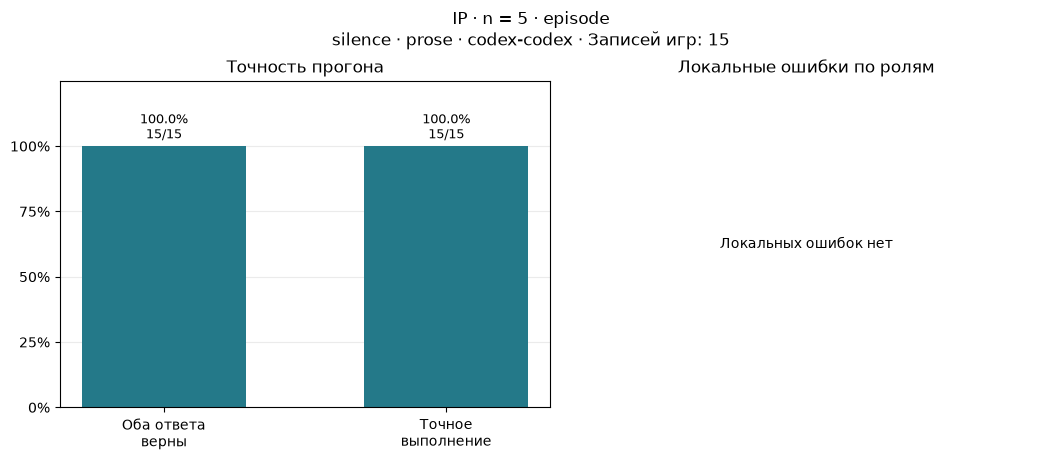

In [33]:
def plot_results(log_path: Path):
    try:
        import matplotlib.pyplot as plt
        from matplotlib.ticker import MaxNLocator
    except ModuleNotFoundError as exc:
        if exc.name != "matplotlib":
            raise
        raise RuntimeError("Установи matplotlib в окружение ядра, затем повтори запуск.") from exc

    errors = {ALICE: Counter(), BOB: Counter()}
    with log_path.open(encoding="utf-8", errors="surrogateescape") as source, StringIO() as report:
        summary = analyze_run(source, report)
        report.seek(0)
        header = json.loads(next(report))
        for line in report:
            row = json.loads(line)
            if row["type"] == "episode":
                for error in row["local_errors"]:
                    errors[error["role"]][error["error"]] += 1
            elif row["type"] == "step" and row["error"] is not None:
                errors[row["state"]["role"]][row["error"]] += 1

    if header["mode"] == "step":
        metrics = (
            ("Ходы", "next_action_accuracy"),
            ("Итоговые\nответы", "output_accuracy"),
            ("Все\nрешения", "decision_accuracy"),
        )
        sample = f"Записей решений: {summary['decision_accuracy']['total']}"
    else:
        metrics = (
            ("Оба ответа\nверны", "joint_accuracy"),
            ("Точное\nвыполнение", "exact_execution"),
        )
        sample = f"Записей игр: {summary['joint_accuracy']['total']}"

    fig, (accuracy_ax, errors_ax) = plt.subplots(1, 2, figsize=(10.5, 4.5), layout="constrained")
    title = f"{header['function'].upper()} · n = {header['n']} · {header['mode']}"
    settings = f"{header['channel']} · {header['explanation']} · {header.get('players', '—')}"
    status = "" if summary["run_complete"] else " · неполный прогон"
    fig.suptitle(f"{title}\n{settings} · {sample}{status}", fontsize=12)

    accuracy_ax.set_title("Точность прогона")
    accuracy_ax.set_ylim(0, 125)
    accuracy_ax.set_yticks(range(0, 101, 25), [f"{p}%" for p in range(0, 101, 25)])
    accuracy_ax.set_xticks(range(len(metrics)), [label for label, _ in metrics])
    accuracy_ax.set_axisbelow(True)
    accuracy_ax.grid(axis="y", alpha=0.25)
    for index, (_, key) in enumerate(metrics):
        metric_row = summary[key]
        rate = metric_row["rate"]
        if rate is None:
            accuracy_ax.text(index, 4, "нет данных", ha="center", fontsize=9)
            continue
        percent = rate * 100
        accuracy_ax.bar(index, percent, color="#247989", width=0.58)
        caption = f"{percent:.1f}%\n{metric_row['count']}/{metric_row['total']}"
        accuracy_ax.text(index, percent + 3, caption, ha="center", fontsize=9)

    errors_ax.set_title("Локальные ошибки по ролям")
    totals = errors[ALICE] + errors[BOB]
    if totals:
        labels = {
            "wrong_action": "Неверный ход",
            "wrong_result_bit": "Неверный бит Боба",
            "wrong_answer": "Неверный итог",
            "wrong_phase": "Ответ не в той фазе",
            "invalid_format": "Недопустимый токен",
        }
        kinds = sorted(totals, key=lambda kind: (-totals[kind], kind))
        positions = range(len(kinds))
        alice_counts = [errors[ALICE][kind] for kind in kinds]
        bob_counts = [errors[BOB][kind] for kind in kinds]
        errors_ax.barh(positions, alice_counts, label="Алиса", color="#6478B8")
        errors_ax.barh(positions, bob_counts, left=alice_counts, label="Боб", color="#C77939")
        errors_ax.set_yticks(positions, [labels.get(kind, kind) for kind in kinds])
        errors_ax.invert_yaxis()
        errors_ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        errors_ax.set_xlabel("Количество ошибок")
        errors_ax.set_axisbelow(True)
        errors_ax.grid(axis="x", alpha=0.25)
        errors_ax.set_xlim(0, max(totals.values()) * 1.08)
        errors_ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
    else:
        errors_ax.set_axis_off()
        has_data = any(summary[key]["total"] for _, key in metrics)
        message = "Локальных ошибок нет" if has_data else "Нет сохранённых записей"
        errors_ax.text(0.5, 0.5, message, ha="center", va="center", transform=errors_ax.transAxes)

    plt.show()
    return fig


plot_log_path = globals().get("log_path")

if plot_log_path is None or not Path(plot_log_path).is_file():
    plot_log_path = max(
        (p for p in Path.cwd().glob("experiment4_*.jsonl")
         if "_analysis_" not in p.name),
        key=lambda p: p.stat().st_mtime_ns,
        default=None,
    )

print("Журнал для графика:", plot_log_path)

if plot_log_path is None:
    print("Для графиков укажи путь к журналу или отчёту в plot_log_path.")
else:
    plot_figure = plot_results(Path(plot_log_path))
    plot_figure.savefig("experiment4_plots.png", dpi=180)